# DSCI 552 — Homework 4

- **Name:** Danmu Agudanmu
- **GitHub Username:** uudam42

In [53]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import statsmodels.api as sm
from joblib import Parallel, delayed
from packaging.version import Version
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score,
                             auc, confusion_matrix, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.dpi"] = 100
SEED = 552

# scikit-learn 1.8 replaced `penalty=` with `l1_ratio` / `C=np.inf`.
# These two helpers build the same models on old and new versions.
NEW_SK = Version(sklearn.__version__) >= Version("1.8")

def logreg_no_penalty(max_iter=100):
    """Plain (unregularized) logistic regression."""
    if NEW_SK:
        return LogisticRegression(C=np.inf, max_iter=max_iter)
    return LogisticRegression(penalty=None, max_iter=max_iter)

def logreg_l1(solver="liblinear", C=1.0, max_iter=5000, tol=1e-4):
    """L1-penalized logistic regression (binary with liblinear, multinomial with saga)."""
    if NEW_SK:
        return LogisticRegression(l1_ratio=1.0, solver=solver, C=C, max_iter=max_iter, tol=tol)
    return LogisticRegression(penalty="l1", solver=solver, C=C, max_iter=max_iter, tol=tol)

print("scikit-learn", sklearn.__version__)

scikit-learn 1.5.1


## Problem 1: Time Series Classification Part 1 — Feature Creation/Extraction

This part was Homework 3. I repeat the code that is needed here (loading, cleaning, train/test split and feature extraction) so this notebook runs on its own.

### Loading and cleaning the data

Same loader as Homework 3: lines starting with `#` are skipped, `bending2/dataset4.csv` is space-separated, and some rows have a trailing comma, so only the first 7 values of each row are kept.

In [55]:
DATA_DIR = Path("../data/AReM")
COLUMNS = ["time", "avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
SERIES = COLUMNS[1:]

def read_arem(path):
    rows = []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            vals = [v for v in re.split(r"[,\s]+", line) if v]
            rows.append([float(v) for v in vals[:7]])
    return pd.DataFrame(rows, columns=COLUMNS)

def file_number(path):
    return int(re.search(r"\d+", path.stem).group())

def is_test(activity, dataset):
    # 1(b): datasets 1-2 of bending1/bending2 and datasets 1-3 of the other folders are test data
    if activity.startswith("bending"):
        return dataset <= 2
    return dataset <= 3

instances = []
for folder in sorted(p for p in DATA_DIR.iterdir() if p.is_dir()):
    for f in sorted(folder.glob("dataset*.csv"), key=file_number):
        ds = file_number(f)
        instances.append({
            "activity": folder.name,
            "dataset": ds,
            "split": "test" if is_test(folder.name, ds) else "train",
            "data": read_arem(f),
        })

meta = pd.DataFrame([{k: d[k] for k in ("activity", "dataset", "split")} for d in instances])
print(f"Number of instances: {len(instances)}")
meta.value_counts(["activity", "split"]).unstack()[["train", "test"]]

Number of instances: 88


split,train,test
activity,,
bending1,5,2
bending2,4,2
cycling,12,3
lying,12,3
sitting,12,3
standing,12,3
walking,12,3


### Feature extraction with $l$ segments

For Homework 4 each time series has to be broken into $l$ pieces of about equal length. `extract_features(l, feats)` splits every one of the 6 series into $l$ consecutive pieces with `np.array_split` and computes the chosen time-domain features on each piece. With $l = 1$ this gives exactly the Homework 3 features.

Column names are `<feature>_<series>` for $l = 1$ and `<feature>_<series>_p<piece>` for $l > 1$. For example `mean_6_p2` is the mean of the second half of series 6 (`var_rss23`) when $l = 2$.

In 1(c)iv of Homework 3 I picked **mean, max and 3rd quartile** as the three most important features, so those are the features used in the rest of this homework.

In [58]:
FEATURE_FUNCS = {
    "min": np.min,
    "max": np.max,
    "mean": np.mean,
    "median": np.median,
    "std": lambda x: np.std(x, ddof=1),
    "1st_quart": lambda x: np.percentile(x, 25),
    "3rd_quart": lambda x: np.percentile(x, 75),
}
SELECTED = ["mean", "max", "3rd_quart"]   # chosen in HW3 1(c)iv

def extract_features(l, feats=SELECTED):
    rows = []
    for d in instances:
        values = d["data"][SERIES].to_numpy()
        pieces = np.array_split(values, l)          # l pieces of (almost) equal length
        row = {}
        for i in range(len(SERIES)):
            for j, piece in enumerate(pieces, start=1):
                for f in feats:
                    name = f"{f}_{i+1}" if l == 1 else f"{f}_{i+1}_p{j}"
                    row[name] = FEATURE_FUNCS[f](piece[:, i])
        rows.append(row)
    return pd.DataFrame(rows)

L_VALUES = range(1, 21)
FEATS = {l: extract_features(l) for l in L_VALUES}   # computed once, reused below

is_train = (meta["split"] == "train").to_numpy()
is_test_ = ~is_train
y_bin = meta["activity"].str.startswith("bending").astype(int).to_numpy()   # 1 = bending
y_multi = meta["activity"].to_numpy()

print("l = 1:", FEATS[1].shape, " l = 2:", FEATS[2].shape, " l = 20:", FEATS[20].shape)
print(f"Training set: {is_train.sum()} instances ({y_bin[is_train].sum()} bending, "
      f"{(1 - y_bin[is_train]).sum()} other)")
print(f"Test set: {is_test_.sum()} instances ({y_bin[is_test_].sum()} bending, "
      f"{(1 - y_bin[is_test_]).sum()} other)")
FEATS[1].head()

l = 1: (88, 18)  l = 2: (88, 36)  l = 20: (88, 360)
Training set: 69 instances (9 bending, 60 other)
Test set: 19 instances (4 bending, 15 other)


,mean_1,max_1,3rd_quart_1,mean_2,max_2,3rd_quart_2,mean_3,max_3,3rd_quart_3,mean_4,max_4,3rd_quart_4,mean_5,max_5,3rd_quart_5,mean_6,max_6,3rd_quart_6
0,40.6248,45.0000,42.0000,0.3586,1.3000,0.5000,19.0409,29.5000,23.2500,0.8325,7.2300,1.1200,34.3113,38.2500,36.0000,0.5706,1.9200,1.3000
1,42.8128,45.6700,43.6700,0.3724,1.2200,0.5000,20.0970,29.5000,22.2500,0.8764,5.7600,1.1450,33.0246,38.5000,34.5000,0.5711,3.1100,1.3000
2,43.9545,47.4000,45.0000,0.4263,1.7000,0.5000,22.1224,29.7500,24.0000,0.4973,4.4400,0.8300,35.5885,38.5000,36.5000,0.4933,1.7900,0.9400
3,42.1798,47.7500,45.0000,0.6960,3.0000,1.1200,22.1836,30.0000,24.3725,0.9899,5.1500,1.3000,33.4939,38.6700,36.3300,0.6135,2.1800,1.0000
4,41.6781,45.7500,42.7500,0.5360,2.8300,0.7100,19.0066,28.2500,22.0625,0.8419,6.4200,1.1200,29.8571,37.5000,31.2500,0.3833,1.7900,0.5000


## Problem 2: Time Series Classification Part 2 — Binary and Multiclass Classification

### 2(a) Binary classification using logistic regression

#### 2(a)i. Scatter plots of mean, max and 3rd quartile of series 1, 2 and 6 (training set)

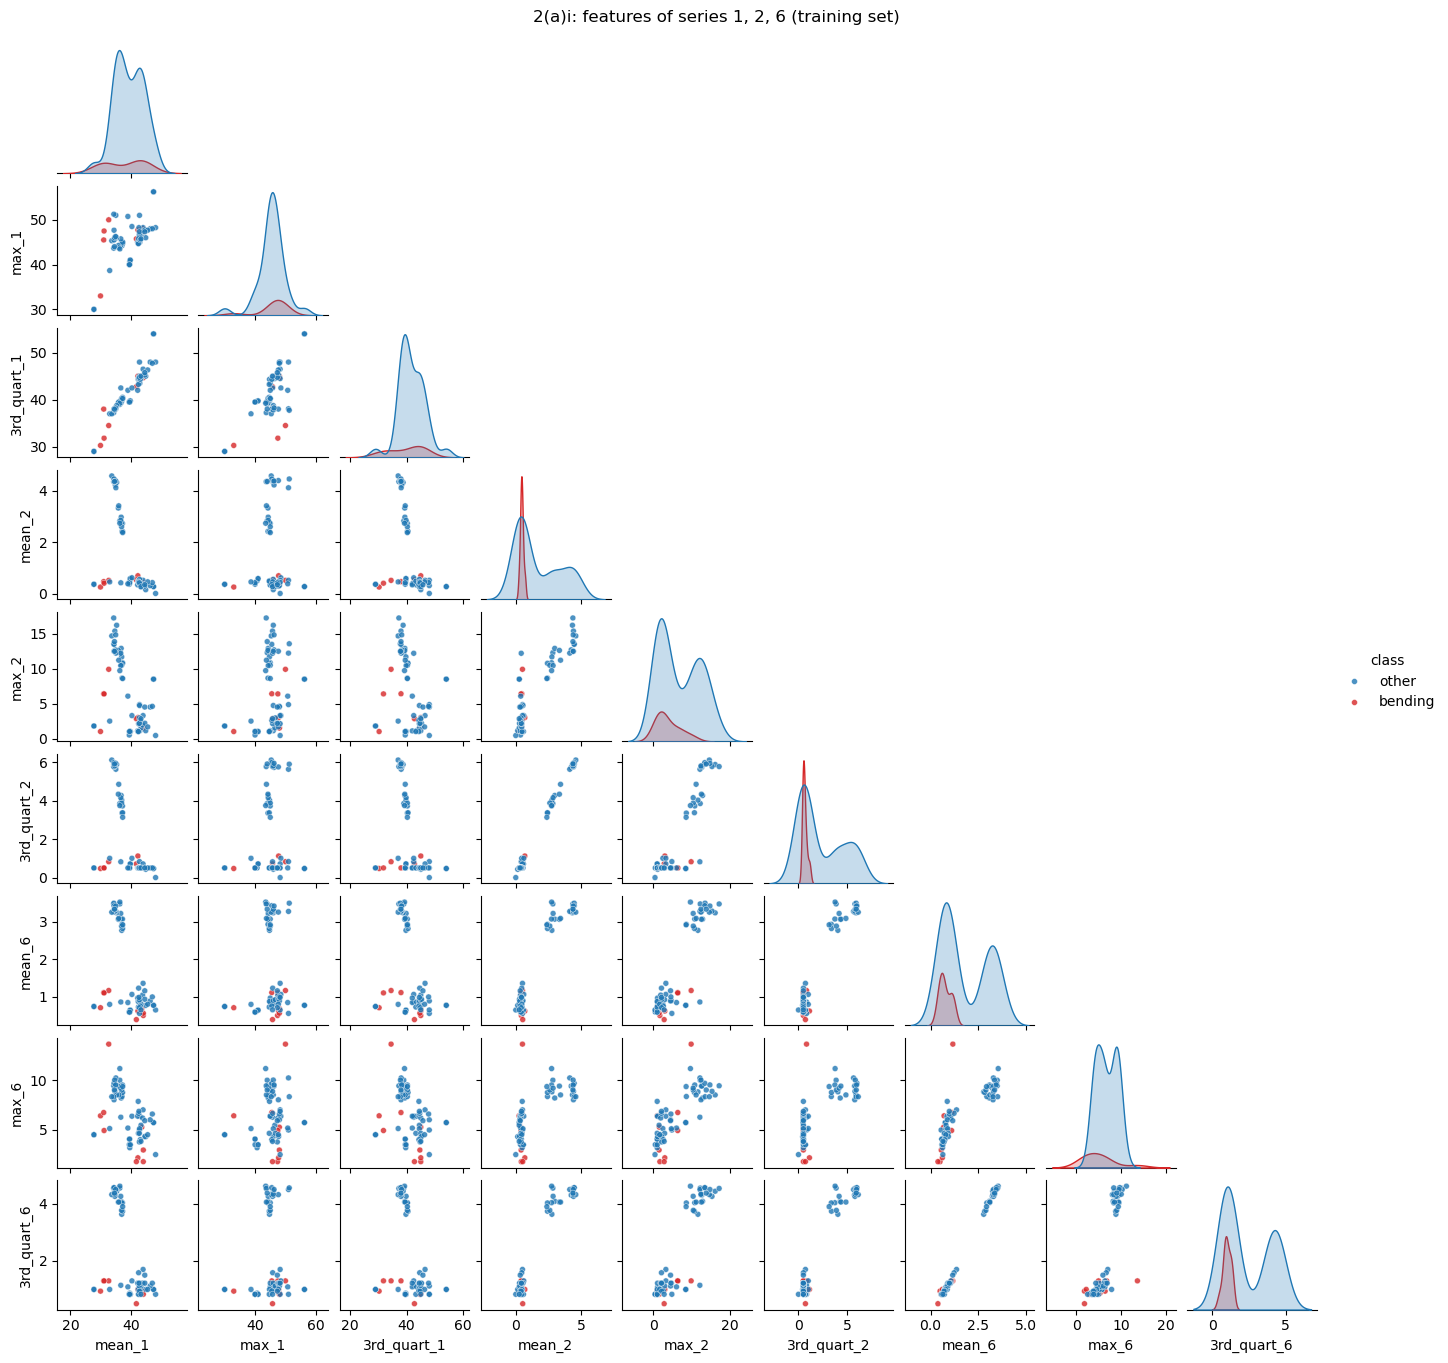

In [61]:
def scatter_matrix(l, series=(1, 2, 6), title=""):
    X = FEATS[l][is_train]
    cols = [c for c in X.columns if int(c.split("_")[-1 if l == 1 else -2]) in series]
    plot_df = X[cols].copy()
    plot_df["class"] = np.where(y_bin[is_train] == 1, "bending", "other")
    g = sns.pairplot(plot_df, hue="class", hue_order=["other", "bending"],
                     palette={"bending": "tab:red", "other": "tab:blue"},
                     plot_kws={"s": 18, "alpha": 0.8}, corner=True, height=1.5)
    g.figure.suptitle(title, y=1.01)
    plt.show()

scatter_matrix(1, title="2(a)i: features of series 1, 2, 6 (training set)")

- Series 2 and 6 (`var_rss12`, `var_rss23`): the bending points (red) are always in the low-variance cluster. This separates bending from the moving activities (cycling, walking), which form a second cluster with large values, but not from the other low-variance activities (lying, sitting, standing).
- Series 1 (`avg_rss12`): bending tends to have a lower mean and 3rd quartile than most other instances, but it overlaps with them.
- No single pair of features separates bending from the rest perfectly, but several features together look useful.

#### 2(a)ii. Same plots after breaking each series into two halves

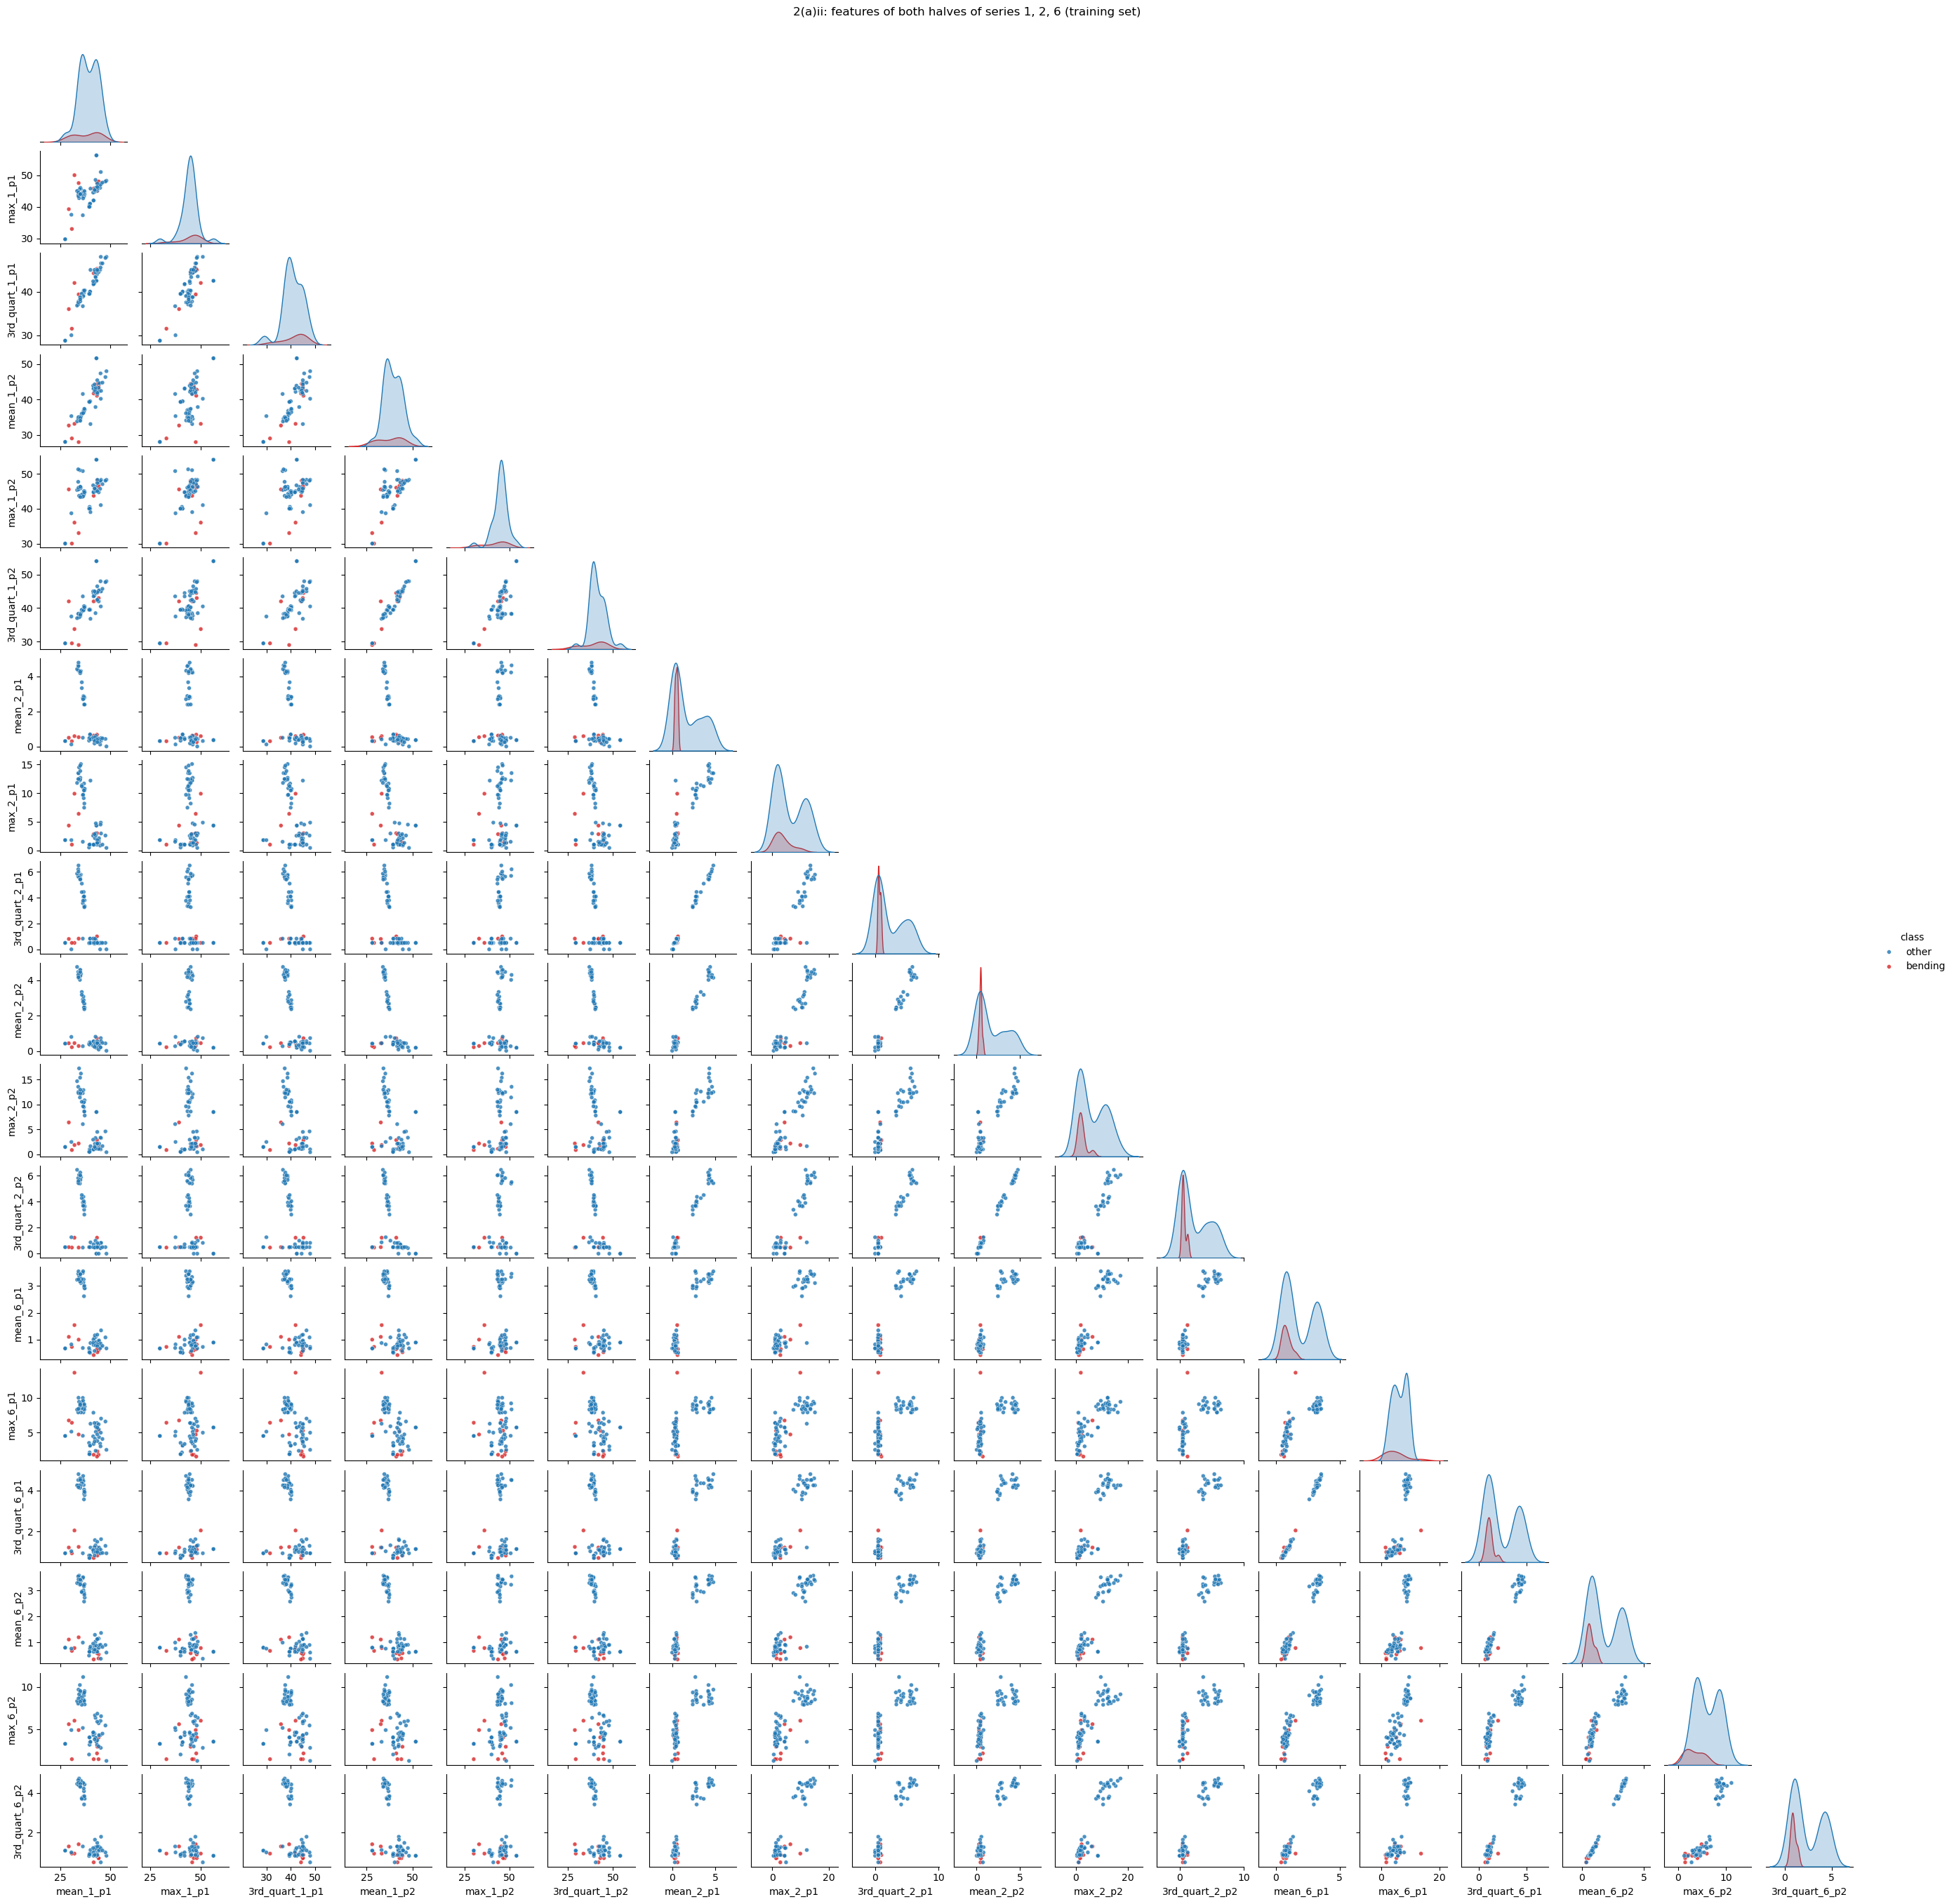

In [64]:
scatter_matrix(2, title="2(a)ii: features of both halves of series 1, 2, 6 (training set)")

No considerable difference. The plots of each half look almost the same as the plots of the whole series in 2(a)i, and the features of the first half are strongly correlated with the same features of the second half (for example `mean_1_p1` vs `mean_1_p2`). This makes sense because each activity is fairly steady over the 480 time steps. Splitting mainly gives more (and partly redundant) features, so the extra plots do not show a new separation.

#### 2(a)iii. Choosing $(l, p)$ with 5-fold cross-validation and recursive feature elimination

**The wrong way and the right way.** Feature selection uses the labels, so it is part of fitting the model.

- *Wrong way:* run RFE (or p-value pruning) on the whole training set to pick the $p$ features, and then use cross-validation only to evaluate logistic regression on those features. The held-out fold already influenced which features were chosen, so the CV accuracy is optimistically biased. With 18$l$ candidate features and only 69 instances this bias can be large: some feature will look predictive by chance.
- *Right way:* for every fold, do *everything* that uses the data (standardization, RFE, fitting the final logistic regression) on the 4 training folds only, and then evaluate on the held-out fold. $l$ and $p$ are chosen by the averaged held-out accuracy.

**Stratified CV.** There are only 9 bending instances out of 69, so an ordinary random 5-fold split could put few or no bending instances in a fold. `StratifiedKFold` keeps the class proportions roughly the same in every fold (here about 2 bending and 12 other instances per fold), so I use it. Because the data set is small, I repeat stratified 5-fold CV 5 times with different shuffles and average, which makes the choice of $(l, p)$ less noisy.

**Details.**
- Features are standardized (inside each fold) so the size of the coefficients, which RFE uses to rank features, is comparable.
- Logistic regression is unregularized ($C = \infty$). Following the footnote, I keep the default `max_iter=100` so the solver stops early instead of blowing up when the classes are separable.
- $l = 1, \dots, 20$ and $p = 1, \dots, 20$ (at $l = 1$ there are only 18 features). RFE with `step=1` removes one feature at a time, so running it once down to 1 feature gives the full elimination order; the top-$p$ features of that ranking are exactly what `RFE(n_features_to_select=p)` would keep. This lets me evaluate all $p$ from one RFE run per fold.
- The p-value method needs a full logistic regression fit first, which is impossible once 18$l$ is close to or larger than the number of instances. So I use the alternative the assignment allows (backward selection with `sklearn.feature_selection.RFE`) and report p-values for the final model in 2(a)iv.

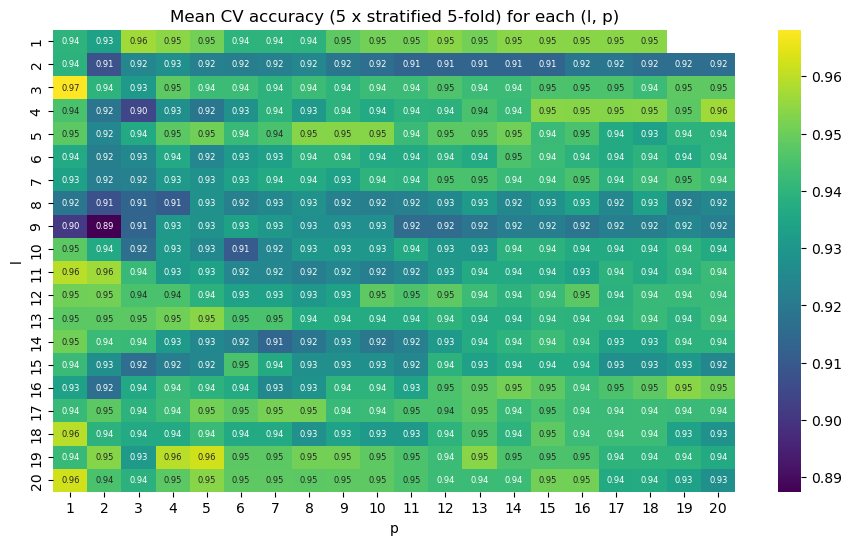

Best (l, p) = (3, 1), CV accuracy = 0.9681


,l,p,acc
0,3,1,0.9681
1,20,1,0.9624
2,19,5,0.9622
3,11,1,0.9593
4,18,1,0.9593
5,19,4,0.9593
6,1,3,0.9567
7,4,20,0.9567
8,11,2,0.9565
9,1,4,0.9541


In [67]:
P_VALUES = range(1, 21)
cv_bin = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
y_tr = y_bin[is_train]
cv_splits = list(cv_bin.split(np.zeros(len(y_tr)), y_tr))

def rfe_fold(l, train_idx, val_idx):
    """Right way: scaling, RFE and the final fit only see the training folds."""
    X = FEATS[l][is_train].to_numpy()
    scaler = StandardScaler().fit(X[train_idx])
    X_fit, X_val = scaler.transform(X[train_idx]), scaler.transform(X[val_idx])
    ranking = RFE(logreg_no_penalty(), n_features_to_select=1, step=1).fit(X_fit, y_tr[train_idx]).ranking_
    acc = {}
    for p in P_VALUES:
        if p > X.shape[1]:
            continue
        keep = ranking <= p
        clf = logreg_no_penalty().fit(X_fit[:, keep], y_tr[train_idx])
        acc[p] = accuracy_score(y_tr[val_idx], clf.predict(X_val[:, keep]))
    return l, acc

results = Parallel(n_jobs=-1)(delayed(rfe_fold)(l, a, b) for l in L_VALUES for a, b in cv_splits)

scores = {}
for l, acc in results:
    for p, a in acc.items():
        scores.setdefault((l, p), []).append(a)
cv_rfe = pd.Series({k: np.mean(v) for k, v in scores.items()}).unstack()
cv_rfe.index.name, cv_rfe.columns.name = "l", "p"

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(cv_rfe, annot=True, fmt=".2f", cmap="viridis", annot_kws={"size": 6}, ax=ax)
ax.set_title("Mean CV accuracy (5 x stratified 5-fold) for each (l, p)")
plt.show()

# best (l, p); ties are broken by the simpler model (smaller l, then smaller p)
best = (cv_rfe.stack().rename("acc").reset_index()
        .sort_values(["acc", "l", "p"], ascending=[False, True, True]))
best_l, best_p = int(best.iloc[0]["l"]), int(best.iloc[0]["p"])
cv_acc_rfe = best.iloc[0]["acc"]
print(f"Best (l, p) = ({best_l}, {best_p}), CV accuracy = {cv_acc_rfe:.4f}")
best.head(10).reset_index(drop=True)

To show why the wrong way is wrong, here is the CV accuracy of the wrong way (RFE run once on the whole training set, then CV) for the same grid, next to the right way.

In [69]:
def wrong_way_cv(l, p):
    X = StandardScaler().fit_transform(FEATS[l][is_train])
    keep = RFE(logreg_no_penalty(), n_features_to_select=p).fit(X, y_tr).support_
    return cross_val_score(logreg_no_penalty(), X[:, keep], y_tr, cv=cv_bin).mean()

compare = pd.DataFrame(
    [{"l": l, "p": p, "right way": cv_rfe.loc[l, p], "wrong way": wrong_way_cv(l, p)}
     for l in (1, 5, 10, 20) for p in (3, 10)])
compare

,l,p,right way,wrong way
0,1,3,0.9567,0.9593
1,1,10,0.9510,0.9626
2,5,3,0.9360,0.9943
3,5,10,0.9536,0.9855
4,10,3,0.9165,0.9536
5,10,10,0.9305,1.0000
6,20,3,0.9391,0.9884
7,20,10,0.9481,1.0000


The wrong way gives higher CV accuracy than the right way in every case, and the gap grows with the number of features (for $l = 10$ or $20$, $p = 10$ it even reaches 100%). This is the selection bias: when RFE has seen all the data, the chosen features fit the held-out folds by chance too. The right way gives an honest estimate.

#### 2(a)iv. Final model on the training data: confusion matrix, ROC/AUC, coefficients and p-values

I refit on the whole training set with the chosen $(l, p)$: standardize, run RFE to keep $p$ features, fit logistic regression. The p-values come from `statsmodels.Logit` fitted on the same standardized features (it gives the same maximum likelihood fit and also the standard errors).

In [72]:
X_tr_best = FEATS[best_l][is_train]
X_te_best = FEATS[best_l][is_test_]
scaler_best = StandardScaler().fit(X_tr_best)
Z_tr = pd.DataFrame(scaler_best.transform(X_tr_best), columns=X_tr_best.columns)
Z_te = pd.DataFrame(scaler_best.transform(X_te_best), columns=X_te_best.columns)

rfe_best = RFE(logreg_no_penalty(), n_features_to_select=best_p).fit(Z_tr, y_tr)
sel_cols = list(Z_tr.columns[rfe_best.support_])
print("Selected features:", sel_cols)

clf_rfe = logreg_no_penalty().fit(Z_tr[sel_cols], y_tr)
prob_tr = clf_rfe.predict_proba(Z_tr[sel_cols])[:, 1]
pred_tr = clf_rfe.predict(Z_tr[sel_cols])

sm_fit = sm.Logit(y_tr, sm.add_constant(Z_tr[sel_cols])).fit(disp=0, maxiter=100)
coef_table = pd.DataFrame({
    "beta (sklearn)": np.r_[clf_rfe.intercept_, clf_rfe.coef_.ravel()],
    "beta (statsmodels)": sm_fit.params.to_numpy(),
    "std. error": sm_fit.bse.to_numpy(),
    "z": sm_fit.tvalues.to_numpy(),
    "p-value": sm_fit.pvalues.to_numpy(),
}, index=["intercept"] + sel_cols)
coef_table

Selected features: ['mean_5_p1']


,beta (sklearn),beta (statsmodels),std. error,z,p-value
intercept,-10.0560,-10.1722,7.2045,-1.4119,0.1580
mean_5_p1,16.7156,16.9281,12.9560,1.3066,0.1914


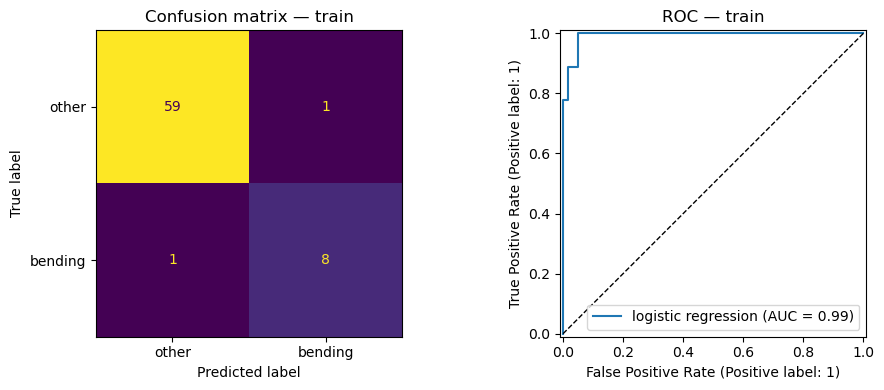

Accuracy = 0.9710, AUC = 0.9926


In [73]:
def show_cm_roc(y_true, y_pred, y_score, title):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, labels=[0, 1]),
                           display_labels=["other", "bending"]).plot(ax=axes[0], colorbar=False)
    axes[0].set_title(f"Confusion matrix — {title}")
    RocCurveDisplay.from_predictions(y_true, y_score, ax=axes[1], name="logistic regression")
    axes[1].plot([0, 1], [0, 1], "k--", lw=1)
    axes[1].set_title(f"ROC — {title}")
    plt.tight_layout()
    plt.show()
    print(f"Accuracy = {accuracy_score(y_true, y_pred):.4f}, AUC = {roc_auc_score(y_true, y_score):.4f}")

show_cm_roc(y_tr, pred_tr, prob_tr, "train")

The best model uses $l = 3$ and only $p = 1$ feature: `mean_5_p1`, the mean of `avg_rss23` in the first third of the series. With so few bending instances, a simple model does best in CV.

- **Confusion matrix (train):** 59 of 60 other and 8 of 9 bending are correct, so the training accuracy is 0.971 (2 errors).
- **ROC / AUC (train):** AUC = 0.993.
- **Coefficients:** $\hat\beta_0 \approx -10.2$ and $\hat\beta_1 \approx 16.9$ (on the standardized feature). A higher `mean_5_p1` means a higher chance of bending.
- **p-values:** 0.158 (intercept) and 0.191 (`mean_5_p1`). The feature is clearly useful, yet the p-value is large. The reason is that the classes are almost perfectly separated by this feature, which makes the standard error very large (12.96). See 2(a)vi.

#### 2(a)v. Test set

The test series are broken into the same $l$ pieces, the features are extracted from the test data, and they are standardized with the scaler fitted on the training data.

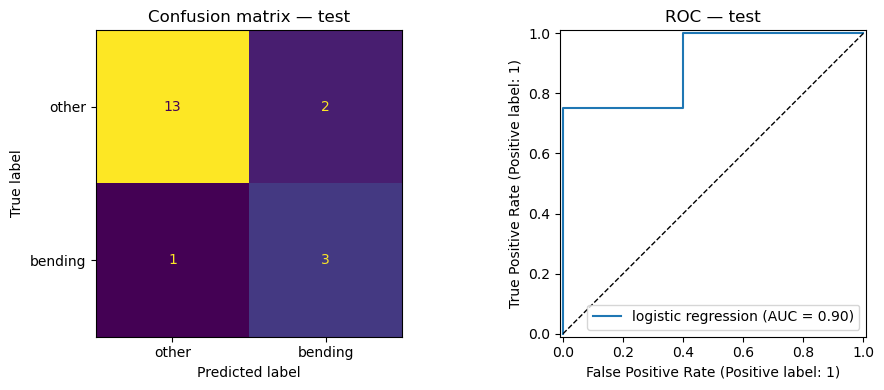

Accuracy = 0.8421, AUC = 0.9000
CV accuracy = 0.9681   Test accuracy = 0.8421


In [76]:
y_te = y_bin[is_test_]
prob_te = clf_rfe.predict_proba(Z_te[sel_cols])[:, 1]
pred_te = clf_rfe.predict(Z_te[sel_cols])
test_acc_rfe = accuracy_score(y_te, pred_te)
show_cm_roc(y_te, pred_te, prob_te, "test")
print(f"CV accuracy = {cv_acc_rfe:.4f}   Test accuracy = {test_acc_rfe:.4f}")

Test accuracy is 0.842 (16 of 19 correct: 2 false positives and 1 missed bending) with AUC = 0.90, which is lower than the CV accuracy of 0.968. The test set is small (19 instances, 4 bending), so one error changes accuracy by about 5%. Also, $(l, p)$ was picked as the maximum over 400 CV scores, so the best CV score is a bit optimistic.

#### 2(a)vi. Are the classes well separated?

In [79]:
# Training accuracy of plain logistic regression on ALL 18*l features: 1.0 means the training data is linearly separable
def train_acc_all(l):
    Z = StandardScaler().fit_transform(FEATS[l][is_train])
    return logreg_no_penalty(max_iter=1000).fit(Z, y_tr).score(Z, y_tr)

print("Training accuracy with all features, for each l:")
print(pd.Series({l: train_acc_all(l) for l in L_VALUES}, name="train acc").round(3).to_frame().T.to_string())

# The final 1-feature model: compare the size of the coefficient with its standard error
print()
print(coef_table[["beta (statsmodels)", "std. error", "p-value"]].to_string())

Training accuracy with all features, for each l:
              1      2      3      4      5      6      7      8      9      10     11     12     13     14     15     16     17     18     19     20
train acc 1.0000 1.0000 1.0000 1.0000 1.0000 1.0000 1.0000 1.0000 1.0000 1.0000 1.0000 1.0000 1.0000 1.0000 1.0000 1.0000 1.0000 1.0000 1.0000 1.0000

           beta (statsmodels)  std. error  p-value
intercept            -10.1722      7.2045   0.1580
mean_5_p1             16.9281     12.9560   0.1914


Yes. With all the features, the training data is perfectly separable for every $l$ (training accuracy 1.0). In that case the maximum likelihood estimate does not exist: the likelihood keeps increasing as the coefficients go to infinity, so the estimates are unstable and depend on when the solver stops. That is why I kept `max_iter` small, as the footnote suggests.

The final 1-feature model is not perfectly separated (2 training errors), so its coefficients are finite, but it is close to separated. This shows up as a very large standard error (12.96 for $\hat\beta_1 = 16.9$) and a large p-value, even though the feature predicts bending well.

#### 2(a)vii. Class imbalance and case-control sampling

The confusion matrices show the imbalance clearly: the training set has 9 bending and 60 other instances (13% vs 87%), and the test set has 4 vs 15.

**Case-control sampling.** Keep all the cases (bending) and sample the same number of controls (other activities) at random, so the sample is 50/50. Fit logistic regression on this balanced sample. Sampling on $y$ only changes the intercept, not the slopes, so the intercept is corrected with

$$\hat\beta_0^{*} = \hat\beta_0 + \log\frac{\pi}{1-\pi} - \log\frac{\tilde\pi}{1-\tilde\pi},$$

where $\pi = 9/69$ is the bending proportion in the training data and $\tilde\pi = 0.5$ is the proportion in the case-control sample. I use the same $l$ and the same selected features as above, and evaluate on the full training set and the test set.

With only 9 controls, one random draw is noisy, so I also repeat the sampling 200 times and report the average AUC.

intercept (adjusted)   -24.6554
mean_5_p1               55.6879


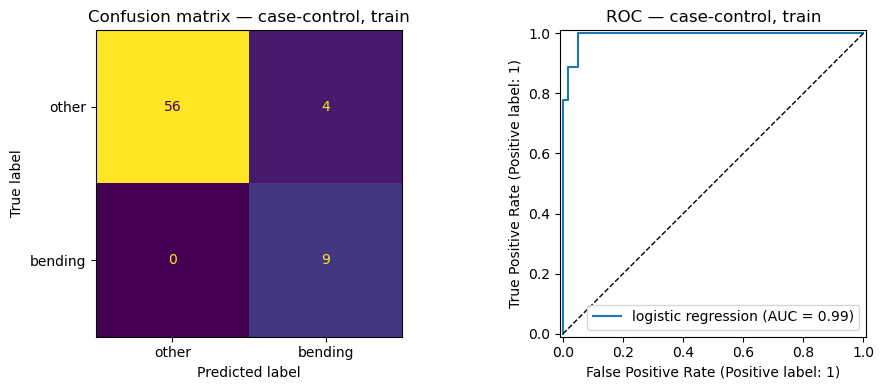

Accuracy = 0.9420, AUC = 0.9926


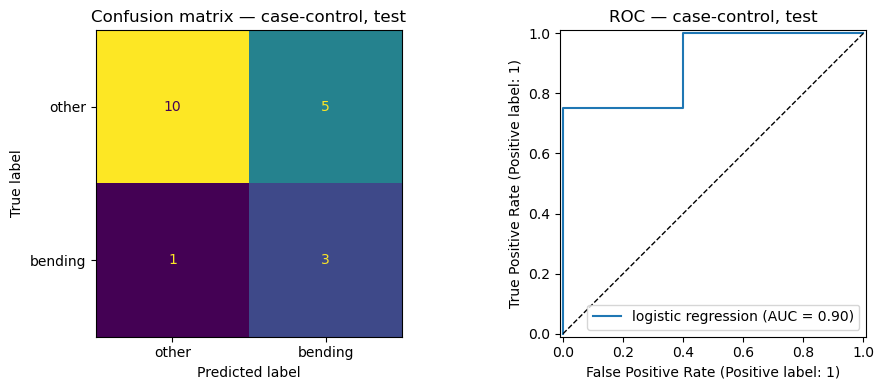

Accuracy = 0.6842, AUC = 0.9000


,train,test
mean AUC,0.9926,0.8988
mean accuracy,0.9552,0.7703


In [82]:
rng = np.random.default_rng(SEED)
cases = np.where(y_tr == 1)[0]
controls = np.where(y_tr == 0)[0]

def case_control_fit(rng):
    idx = np.r_[cases, rng.choice(controls, size=len(cases), replace=False)]
    m = logreg_no_penalty().fit(Z_tr.iloc[idx][sel_cols], y_tr[idx])
    pi, pi_s = y_tr.mean(), y_tr[idx].mean()
    m.intercept_ = m.intercept_ + np.log(pi / (1 - pi)) - np.log(pi_s / (1 - pi_s))
    return m

cc_model = case_control_fit(rng)
print(pd.Series(np.r_[cc_model.intercept_, cc_model.coef_.ravel()],
                index=["intercept (adjusted)"] + sel_cols, name="beta").to_string())

for name, Z, yy in [("train", Z_tr, y_tr), ("test", Z_te, y_te)]:
    show_cm_roc(yy, cc_model.predict(Z[sel_cols]), cc_model.predict_proba(Z[sel_cols])[:, 1],
                f"case-control, {name}")

rep = [case_control_fit(rng) for _ in range(200)]
rep_table = pd.DataFrame({
    name: {"mean AUC": np.mean([roc_auc_score(yy, m.predict_proba(Z[sel_cols])[:, 1]) for m in rep]),
           "mean accuracy": np.mean([m.score(Z[sel_cols], yy) for m in rep])}
    for name, Z, yy in [("train", Z_tr, y_tr), ("test", Z_te, y_te)]})
rep_table

Yes, the classes are imbalanced (9 vs. 60 in training, 4 vs. 15 in test).

The case-control model gives AUC = 0.993 (train) and 0.900 (test), the same as before. This is expected: with one feature, the slope only changes how fast the probability rises, and the ranking of instances (which is all that ROC/AUC uses) does not change. The accuracy goes down (0.942 on train, 0.684 on test, with 5 of the 15 test "other" instances called bending). With only 9 controls, the fitted slope is much steeper (55.7 vs 16.9) because the small balanced sample is almost perfectly separated, so the estimate is unstable. Averaged over 200 random samples, the test AUC is about 0.90 and test accuracy 0.77. So case-control sampling does not help here; it is mainly useful when there are far more controls than we can afford to use.

### 2(b) Binary classification using L1-penalized logistic regression

#### 2(b)i. Cross-validating $l$ and $C$

Now the feature selection is done by the L1 penalty instead of p-values/RFE. For each $l$ I use `GridSearchCV` over the budget $C = 1/\lambda$ with a pipeline (`StandardScaler` → L1 logistic regression with the `liblinear` solver), so the scaling is fitted inside each fold (the right way). The same repeated stratified 5-fold splits are used as in 2(a)iii. Ties are broken by smaller $l$ and then smaller $C$ (sparser model).

Best l = 12, C = 1 (lambda = 1), CV accuracy = 0.9738


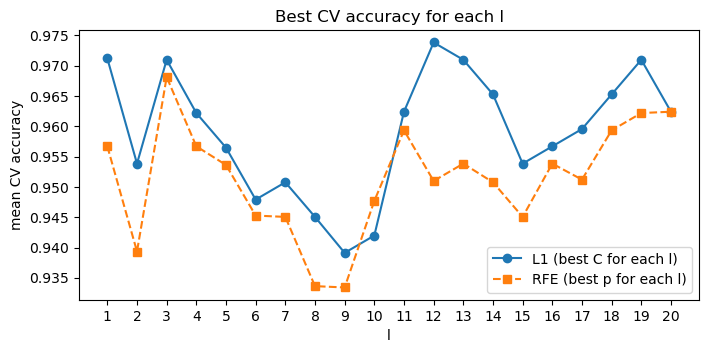

In [85]:
C_GRID = np.logspace(-2, 3, 21)

def l1_pipeline(solver="liblinear", max_iter=5000, tol=1e-4):
    return Pipeline([("scale", StandardScaler()), ("clf", logreg_l1(solver=solver, max_iter=max_iter, tol=tol))])

def grid_over_l(make_pipe, y, cv, param_grid, scoring="accuracy"):
    rows = []
    for l in L_VALUES:
        gs = GridSearchCV(make_pipe(), param_grid, cv=cv, scoring=scoring, n_jobs=-1)
        gs.fit(FEATS[l][is_train], y[is_train])
        for params, score in zip(gs.cv_results_["params"], gs.cv_results_["mean_test_score"]):
            rows.append({"l": l, **{k.split("__")[-1]: v for k, v in params.items()}, "acc": score})
    return pd.DataFrame(rows)

cv_l1 = grid_over_l(l1_pipeline, y_bin, cv_bin, {"clf__C": C_GRID})
best_l1 = cv_l1.sort_values(["acc", "l", "C"], ascending=[False, True, True]).iloc[0]
l1_l, l1_C, cv_acc_l1 = int(best_l1["l"]), best_l1["C"], best_l1["acc"]
print(f"Best l = {l1_l}, C = {l1_C:.4g} (lambda = {1 / l1_C:.4g}), CV accuracy = {cv_acc_l1:.4f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(cv_l1.groupby("l")["acc"].max(), "o-", label="L1 (best C for each l)")
ax.plot(cv_rfe.max(axis=1), "s--", label="RFE (best p for each l)")
ax.set(xlabel="l", ylabel="mean CV accuracy", xticks=list(L_VALUES), title="Best CV accuracy for each l")
ax.legend()
plt.show()

Non-zero coefficients: 4 of 216
mean_5_p2     2.3050
max_1_p7     -0.6771
max_6_p11    -0.6520
mean_5_p11    0.3704


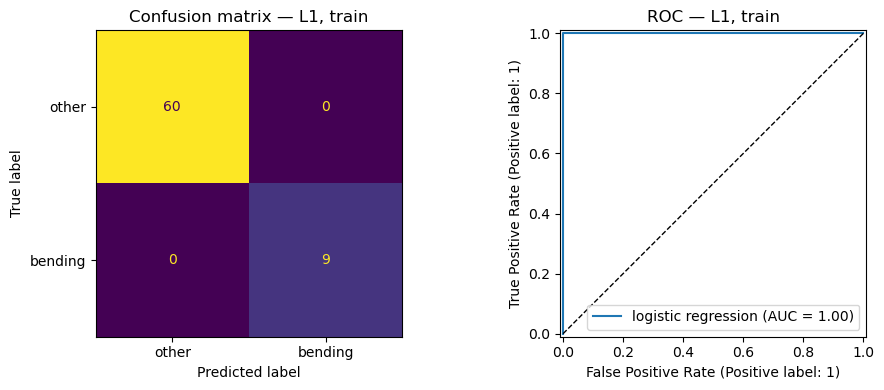

Accuracy = 1.0000, AUC = 1.0000


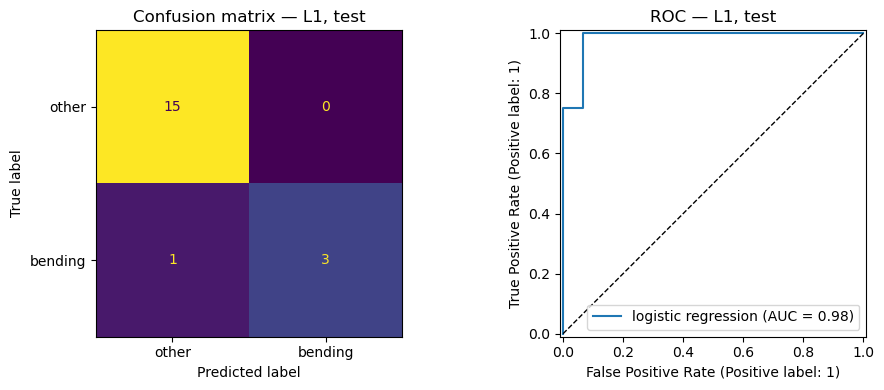

Accuracy = 0.9474, AUC = 0.9833


In [86]:
l1_model = l1_pipeline().set_params(clf__C=l1_C).fit(FEATS[l1_l][is_train], y_tr)
coefs = pd.Series(l1_model["clf"].coef_.ravel(), index=FEATS[l1_l].columns)
print(f"Non-zero coefficients: {(coefs != 0).sum()} of {len(coefs)}")
print(coefs[coefs != 0].sort_values(key=abs, ascending=False).to_string())

for name, mask in [("train", is_train), ("test", is_test_)]:
    X, yy = FEATS[l1_l][mask], y_bin[mask]
    show_cm_roc(yy, l1_model.predict(X), l1_model.predict_proba(X)[:, 1], f"L1, {name}")
test_acc_l1 = l1_model.score(FEATS[l1_l][is_test_], y_te)

#### 2(b)ii. L1 penalty vs. variable selection with p-values / RFE

In [88]:
pd.DataFrame({
    "l": [best_l, l1_l],
    "features used": [best_p, int((coefs != 0).sum())],
    "CV accuracy": [cv_acc_rfe, cv_acc_l1],
    "test accuracy": [test_acc_rfe, test_acc_l1],
    "test AUC": [roc_auc_score(y_te, prob_te),
                 roc_auc_score(y_te, l1_model.predict_proba(FEATS[l1_l][is_test_])[:, 1])],
}, index=["RFE / p-values (2a)", "L1-penalized (2b)"])

,l,features used,CV accuracy,test accuracy,test AUC
RFE / p-values (2a),3,1,0.9681,0.8421,0.9000
L1-penalized (2b),12,4,0.9738,0.9474,0.9833


- **Performance:** the L1-penalized model is better. It has higher CV accuracy (0.974 vs 0.968) and a clearly better test result (accuracy 0.947 vs 0.842, AUC 0.983 vs 0.900). It keeps 4 of 216 features at $l = 12$.
- **Ease of implementation:** L1 is easier. Selection and fitting are one step, and only $C$ has to be tuned (`GridSearchCV` does it). Selection by p-values / RFE needs a separate selection loop inside every CV fold, and the p-values are unreliable here because the classes are (almost) separable.

### 2(c) Multi-class classification

#### 2(c)i. L1-penalized multinomial regression

Now all 7 activity folders are separate classes (bending1 and bending2 are different bending types, see `bendingType.pdf`). I use the `saga` solver, which supports the L1 penalty with the multinomial (softmax) loss, inside the same scaling pipeline and choose $(l, C)$ the same way as in 2(b)i.

Stratified 5-fold CV is used again (one round, because the `saga` solver is slow). bending2 has only 4 training instances, so one fold gets none of them; scikit-learn warns about this but it still works.

**Multi-class confusion matrix and ROC.** A $K$-class confusion matrix is $K \times K$: entry $(i, j)$ counts test instances of true class $i$ predicted as class $j$, so the diagonal holds the correct predictions. ROC curves are defined for two classes, so for $K$ classes the usual approach is **one-vs-rest**: for each class $k$, treat "$k$" as positive and all other classes as negative, and use the predicted probability $P(y = k \mid x)$ as the score. This gives $K$ ROC curves and $K$ AUCs. They are summarized by the **macro-average** (average of the $K$ AUCs, every class counts the same) or the **micro-average** (pool all $K$ one-vs-rest decisions into one big binary problem, so larger classes count more).

In [91]:
CLASSES = sorted(np.unique(y_multi))
# saga is much slower than liblinear, so here I use one round of stratified 5-fold CV and a smaller C grid
cv_multi = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
C_GRID_MULTI = np.logspace(-1, 2, 7)

cv_mn = grid_over_l(lambda: l1_pipeline(solver="saga", max_iter=5000, tol=1e-3), y_multi, cv_multi,
                    {"clf__C": C_GRID_MULTI})
best_mn = cv_mn.sort_values(["acc", "l", "C"], ascending=[False, True, True]).iloc[0]
mn_l, mn_C, cv_acc_mn = int(best_mn["l"]), best_mn["C"], best_mn["acc"]
print(f"Best l = {mn_l}, C = {mn_C:.4g}, CV accuracy = {cv_acc_mn:.4f}")

mn_model = l1_pipeline(solver="saga", max_iter=5000, tol=1e-3).set_params(clf__C=mn_C)
mn_model.fit(FEATS[mn_l][is_train], y_multi[is_train])
n_nonzero = int((np.abs(mn_model["clf"].coef_).sum(axis=0) > 0).sum())
print(f"Features with a non-zero coefficient for at least one class: {n_nonzero} of {FEATS[mn_l].shape[1]}")

Best l = 1, C = 10, CV accuracy = 0.9418
Features with a non-zero coefficient for at least one class: 18 of 18


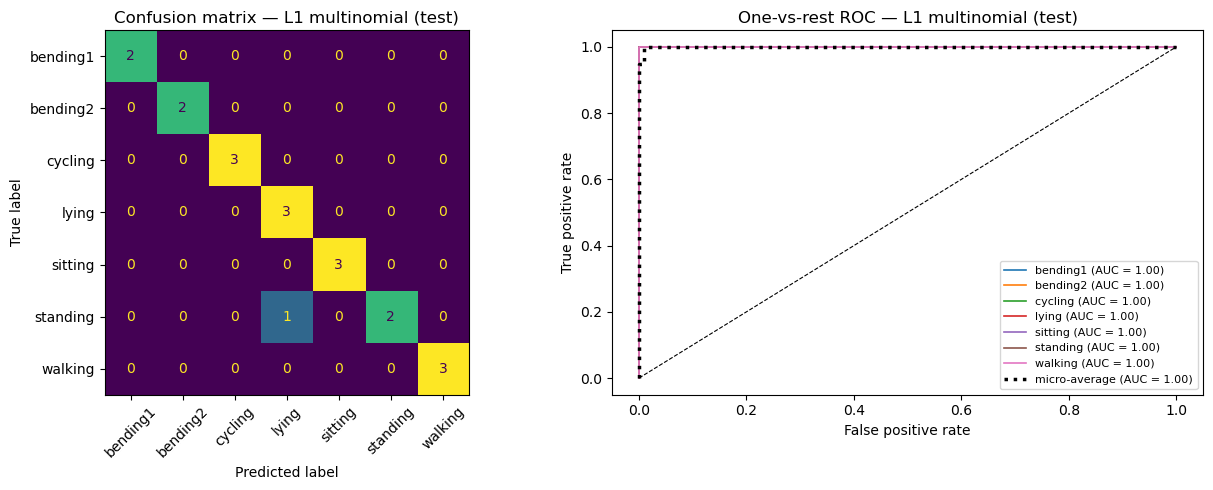

Test error = 0.0526 (accuracy = 0.9474)


,bending1,bending2,cycling,lying,sitting,standing,walking,micro-average,macro-average
AUC,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.9995,1.0000


In [92]:
def multiclass_report(model, X_te, y_true, title):
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)
    classes = list(model.classes_)
    err = 1 - accuracy_score(y_true, pred)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    ConfusionMatrixDisplay(confusion_matrix(y_true, pred, labels=classes),
                           display_labels=classes).plot(ax=axes[0], colorbar=False, xticks_rotation=45)
    axes[0].set_title(f"Confusion matrix — {title} (test)")

    Y = label_binarize(y_true, classes=classes)
    aucs = {}
    for k, c in enumerate(classes):
        fpr, tpr, _ = roc_curve(Y[:, k], proba[:, k])
        aucs[c] = auc(fpr, tpr)
        axes[1].plot(fpr, tpr, lw=1.2, label=f"{c} (AUC = {aucs[c]:.2f})")
    fpr, tpr, _ = roc_curve(Y.ravel(), proba.ravel())
    aucs["micro-average"] = auc(fpr, tpr)
    aucs["macro-average"] = np.mean([aucs[c] for c in classes])
    axes[1].plot(fpr, tpr, "k:", lw=2.5, label=f"micro-average (AUC = {aucs['micro-average']:.2f})")
    axes[1].plot([0, 1], [0, 1], "k--", lw=0.8)
    axes[1].set(xlabel="False positive rate", ylabel="True positive rate",
                title=f"One-vs-rest ROC — {title} (test)")
    axes[1].legend(fontsize=8, loc="lower right")
    plt.tight_layout()
    plt.show()
    print(f"Test error = {err:.4f} (accuracy = {1 - err:.4f})")
    return err, pd.Series(aucs, name="AUC")

mn_err, mn_auc = multiclass_report(mn_model, FEATS[mn_l][is_test_], y_multi[is_test_], "L1 multinomial")
mn_auc.to_frame().T

The best model uses $l = 1$ and $C = 10$, with CV accuracy 0.942. The test error is **0.053**: 18 of 19 test instances are correct, and the only error is one standing instance predicted as lying. The one-vs-rest AUC is 1.00 for every class (micro-average 0.9995): even the misclassified instance still gets a higher "standing" probability than all non-standing instances.

#### 2(c)ii. Naïve Bayes with Gaussian and Multinomial models

I choose $l$ for each Naïve Bayes model with the same stratified 5-fold CV as in 2(c)i.

- **Gaussian NB** assumes each feature is normal within each class. It is invariant to rescaling each feature, so no scaling is needed.
- **Multinomial NB** treats the features like counts and needs non-negative values. All the features here (mean, max, 3rd quartile of RSS values and variances) are already $\geq 0$, so I use them directly. I also tune the smoothing parameter $\alpha$.

Gaussian NB:    best l = 7, CV accuracy = 0.8846
Multinomial NB: best l = 4, alpha = 0.1, CV accuracy = 0.8835


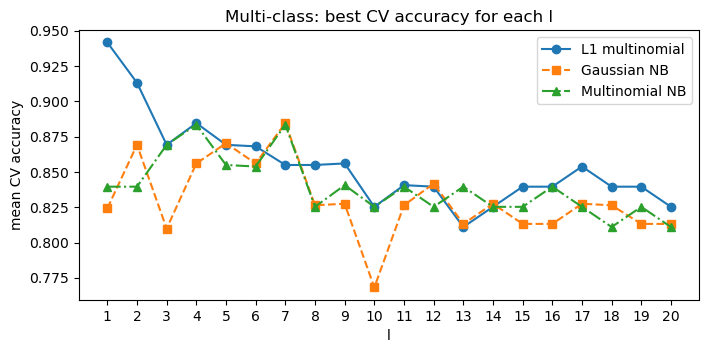

In [95]:
cv_gnb = grid_over_l(lambda: Pipeline([("clf", GaussianNB())]), y_multi, cv_multi,
                     {"clf__var_smoothing": [1e-9]})
cv_mnb = grid_over_l(lambda: Pipeline([("clf", MultinomialNB())]), y_multi, cv_multi,
                     {"clf__alpha": [0.01, 0.1, 1.0, 10.0]})

best_gnb = cv_gnb.sort_values(["acc", "l"], ascending=[False, True]).iloc[0]
best_mnb = cv_mnb.sort_values(["acc", "l", "alpha"], ascending=[False, True, False]).iloc[0]
gnb_l, mnb_l, mnb_alpha = int(best_gnb["l"]), int(best_mnb["l"]), best_mnb["alpha"]
print(f"Gaussian NB:    best l = {gnb_l}, CV accuracy = {best_gnb['acc']:.4f}")
print(f"Multinomial NB: best l = {mnb_l}, alpha = {mnb_alpha}, CV accuracy = {best_mnb['acc']:.4f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(cv_mn.groupby("l")["acc"].max(), "o-", label="L1 multinomial")
ax.plot(cv_gnb.groupby("l")["acc"].max(), "s--", label="Gaussian NB")
ax.plot(cv_mnb.groupby("l")["acc"].max(), "^-.", label="Multinomial NB")
ax.set(xlabel="l", ylabel="mean CV accuracy", xticks=list(L_VALUES), title="Multi-class: best CV accuracy for each l")
ax.legend()
plt.show()

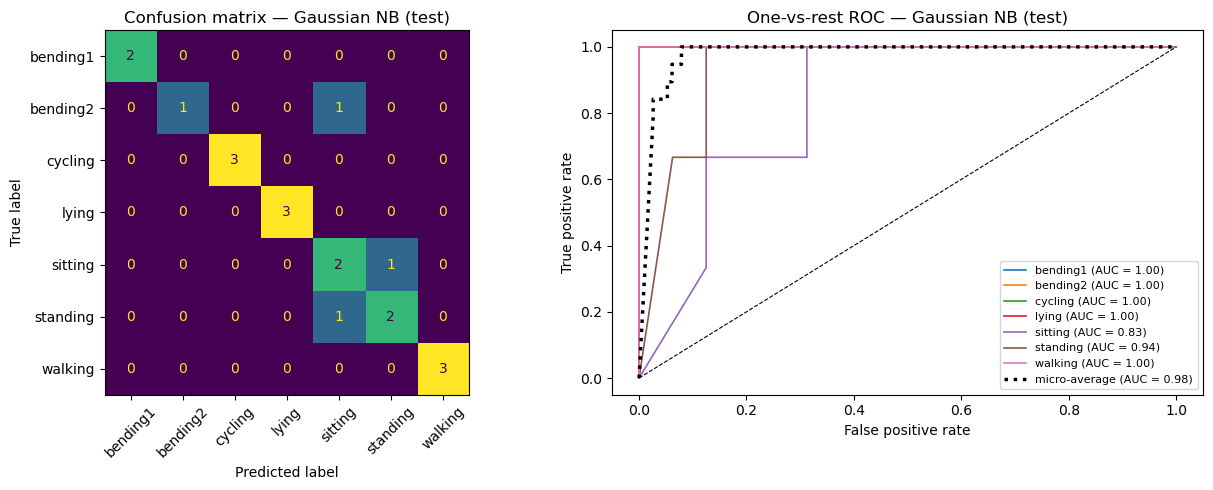

Test error = 0.1579 (accuracy = 0.8421)


In [96]:
gnb_model = GaussianNB().fit(FEATS[gnb_l][is_train], y_multi[is_train])
gnb_err, gnb_auc = multiclass_report(gnb_model, FEATS[gnb_l][is_test_], y_multi[is_test_], "Gaussian NB")

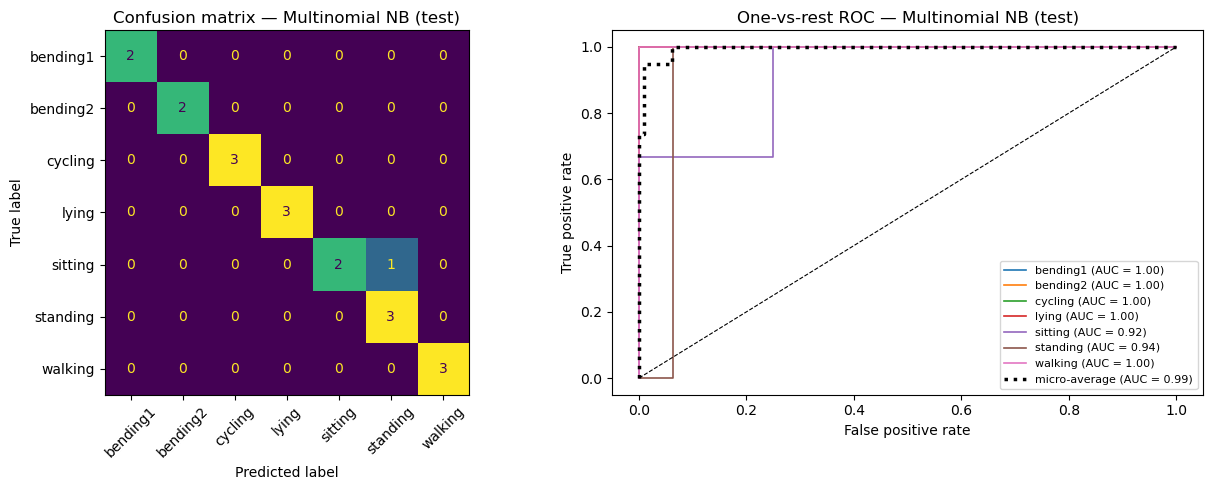

Test error = 0.0526 (accuracy = 0.9474)


In [97]:
mnb_model = MultinomialNB(alpha=mnb_alpha).fit(FEATS[mnb_l][is_train], y_multi[is_train])
mnb_err, mnb_auc = multiclass_report(mnb_model, FEATS[mnb_l][is_test_], y_multi[is_test_], "Multinomial NB")

#### 2(c)iii. Which method is better?

In [99]:
summary = pd.DataFrame({
    "l": [mn_l, gnb_l, mnb_l],
    "CV accuracy": [cv_acc_mn, best_gnb["acc"], best_mnb["acc"]],
    "test error": [mn_err, gnb_err, mnb_err],
    "test macro AUC": [mn_auc["macro-average"], gnb_auc["macro-average"], mnb_auc["macro-average"]],
    "test micro AUC": [mn_auc["micro-average"], gnb_auc["micro-average"], mnb_auc["micro-average"]],
}, index=["L1 multinomial regression", "Gaussian NB", "Multinomial NB"])
summary

,l,CV accuracy,test error,test macro AUC,test micro AUC
L1 multinomial regression,1,0.9418,0.0526,1.0000,0.9995
Gaussian NB,7,0.8846,0.1579,0.9673,0.9781
Multinomial NB,4,0.8835,0.0526,0.9792,0.9949


**L1-penalized multinomial regression is the best method here.** It has the highest CV accuracy (0.942 vs about 0.88 for both Naïve Bayes models), the lowest test error (0.053) and the highest AUC.

Between the two Naïve Bayes models, Multinomial NB did better on the test set (error 0.053 vs 0.158), but their CV accuracy is about the same, so with only 19 test instances this difference is not reliable. Both NB models mostly confuse sitting and standing. Naïve Bayes assumes the features are independent within a class, but here they are strongly correlated (mean, max and 3rd quartile of the same series, and of neighboring pieces), which hurts it. Logistic regression does not need this assumption.

## Problem 3: ISLR 4.8.3

One predictor, $K$ classes, $X \mid Y = k \sim N(\mu_k, \sigma_k^2)$ with a class-specific variance. Prove the Bayes classifier is quadratic, not linear.

The Bayes classifier assigns $x$ to the class with the largest posterior

$$p_k(x) = \frac{\pi_k f_k(x)}{\sum_{l=1}^{K} \pi_l f_l(x)}, \qquad f_k(x) = \frac{1}{\sqrt{2\pi}\,\sigma_k} \exp\!\left(-\frac{(x - \mu_k)^2}{2\sigma_k^2}\right).$$

The denominator is the same for every $k$, and $\log$ is increasing, so maximizing $p_k(x)$ is the same as maximizing $\log\big(\pi_k f_k(x)\big)$:

$$\log\big(\pi_k f_k(x)\big) = \log \pi_k - \tfrac{1}{2}\log(2\pi) - \log \sigma_k - \frac{(x - \mu_k)^2}{2\sigma_k^2}.$$

Dropping the constant $-\tfrac12\log(2\pi)$ (same for every class) and expanding the square gives the discriminant

$$\delta_k(x) = -\frac{x^2}{2\sigma_k^2} + \frac{\mu_k}{\sigma_k^2}\,x - \frac{\mu_k^2}{2\sigma_k^2} + \log \pi_k - \log \sigma_k,$$

and the Bayes classifier assigns $x$ to $\arg\max_k \delta_k(x)$.

In LDA all $\sigma_k = \sigma$, so the term $-x^2/(2\sigma^2)$ is the same for every class and cancels when classes are compared, which leaves a linear function of $x$. Here the $\sigma_k$ differ, so the coefficient $-1/(2\sigma_k^2)$ of $x^2$ is different for each class and does not cancel: the decision boundary between classes $k$ and $l$, $\delta_k(x) = \delta_l(x)$, is

$$\left(\frac{1}{2\sigma_l^2} - \frac{1}{2\sigma_k^2}\right)x^2 + \left(\frac{\mu_k}{\sigma_k^2} - \frac{\mu_l}{\sigma_l^2}\right)x + \left(\frac{\mu_l^2}{2\sigma_l^2} - \frac{\mu_k^2}{2\sigma_k^2} + \log\frac{\pi_k \sigma_l}{\pi_l \sigma_k}\right) = 0,$$

which is a quadratic equation in $x$ whenever $\sigma_k \neq \sigma_l$. So the Bayes classifier is quadratic, not linear. $\blacksquare$

## Problem 4: ISLR 4.8.7

Predict whether a company issues a dividend (Yes/No) from last year's percent profit $X$. $\bar X = 10$ for companies that issued a dividend, $\bar X = 0$ for those that did not, $\hat\sigma^2 = 36$ for both, and 80% of companies issued dividends. $X$ is normal within each class. Find $P(\text{Yes} \mid X = 4)$.

By Bayes' theorem with normal densities (the factor $1/\sqrt{2\pi\sigma^2}$ is the same for both classes and cancels):

$$P(\text{Yes} \mid X = 4) = \frac{\pi_{\text{Yes}} \exp\!\left(-\frac{(4 - 10)^2}{2 \cdot 36}\right)}{\pi_{\text{Yes}} \exp\!\left(-\frac{(4 - 10)^2}{2 \cdot 36}\right) + \pi_{\text{No}} \exp\!\left(-\frac{(4 - 0)^2}{2 \cdot 36}\right)} = \frac{0.8\, e^{-1/2}}{0.8\, e^{-1/2} + 0.2\, e^{-2/9}}.$$

In [102]:
num = 0.8 * np.exp(-(4 - 10) ** 2 / (2 * 36))
den = num + 0.2 * np.exp(-(4 - 0) ** 2 / (2 * 36))
print(f"0.8 e^(-1/2) = {num:.4f},  0.2 e^(-2/9) = {den - num:.4f}")
print(f"P(Yes | X = 4) = {num / den:.4f}")

0.8 e^(-1/2) = 0.4852,  0.2 e^(-2/9) = 0.1601
P(Yes | X = 4) = 0.7519


$$P(\text{Yes} \mid X = 4) = \frac{0.4852}{0.4852 + 0.1601} \approx \mathbf{0.752}.$$

So a company with 4% profit last year has about a 75.2% probability of issuing a dividend this year.